# 07 - Analyses bonus sur le modèle général retenu

1. **Lissage temporel des prédictions** : exploiter le fait qu'un comportement dure plusieurs secondes ;
2. **UMAP des erreurs** : où se situent les erreurs dans l'espace des variables ?
3. **Prédiction conforme** : quantifier l'incertitude par des ensembles de prédiction à couverture garantie.

Chaque analyse respecte la règle du projet : aucun réglage n'est fait sur le test.

In [1]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import json
from src import data, labels, modeling, evaluation, smoothing, conformal, viz

In [2]:
windows = data.load_table(cfg.WINDOWS_FILE)
dogs = data.load_dogs()
train_ids, test_ids = data.load_split()
pointeur = json.loads((cfg.TABLES_DIR / "meilleur_modele_general.json").read_text())
general = modeling.load_bundle(**pointeur)
classes = list(general["label_encoder"].classes_)

# Même tâche et même filtrage qu'au notebook 04
task = labels.select_task_windows(windows, "general", min_purity=cfg.MIN_PURITY)
task = task.merge(dogs[["DogID"] + cfg.STATIC_FEATURES], on="DogID", how="left")
task = task[task["target"].isin(classes)]
train, test = task[task["DogID"].isin(train_ids)], task[task["DogID"].isin(test_ids)]
print(f"Modèle général : {general['model_name']} / {general['experiment']} | {len(classes)} classes")
print(f"Train : {len(train):,} fenêtres | Test : {len(test):,} fenêtres")

pred_test = data.load_table(cfg.PROCESSED_DIR / "predictions_test_general.parquet")
pred_test = pred_test.set_index("window_id").loc[test["window_id"]].reset_index()
proba_test = pred_test[[f"proba_{c}" for c in classes]].to_numpy()
le = general["label_encoder"]

Modèle général : XGBoost / multi_echelle | 11 classes
Train : 93,124 fenêtres | Test : 27,654 fenêtres


## 1. Lissage temporel

On moyenne les probabilités de `k` fenêtres consécutives (fenêtre centrée), sans traverser de rupture.
Le choix de `k` se fait sur des **prédictions hors-pli du train** (chaque fenêtre prédite par un modèle qui
n'a pas vu son chien), jamais sur le test. Le lissage n'utilise que les prédictions : aucune fuite de label.


Limite : la fenêtre centrée utilise le « futur » ; en temps réel il faudrait un lissage causal (lié au passé par exemple).

,k,duree_lissage_s,f1_macro_oof_train
0,1,1.0,0.7070
1,3,2.0,0.7129
2,5,3.0,0.7173
3,7,4.0,0.7189
4,9,5.0,0.7217
5,11,6.0,0.7248
6,15,8.0,0.7254
7,21,11.0,0.7264
8,31,16.0,0.7236
9,41,21.0,0.7226


k retenu sur le train : 21 fenêtres (~11.0 s)


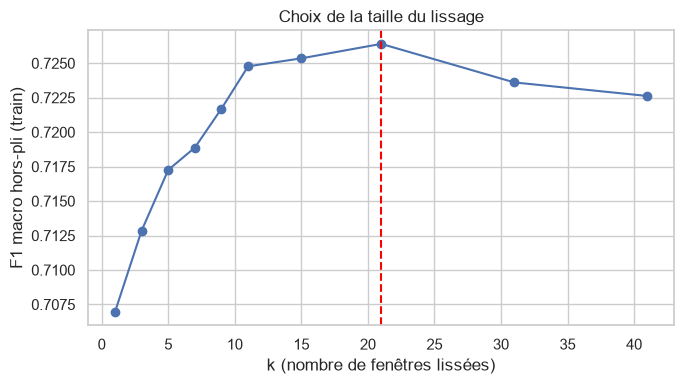

In [3]:
oof = modeling.oof_predict_proba(general, train)          # long : 5 réentraînements
y_train = le.transform(train["target"])
choix_k = smoothing.choose_k(oof, y_train, train, ks=(1, 3, 5, 7, 9, 11, 15, 21, 31, 41))
display(choix_k.round(4))
k_opt = int(choix_k.loc[choix_k["f1_macro_oof_train"].idxmax(), "k"])
print(f"k retenu sur le train : {k_opt} fenêtres (~{choix_k.set_index('k').loc[k_opt, 'duree_lissage_s']} s)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(choix_k["k"], choix_k["f1_macro_oof_train"], marker="o")
ax.axvline(k_opt, color="red", ls="--"); ax.set_xlabel("k (nombre de fenêtres lissées)")
ax.set_ylabel("F1 macro hors-pli (train)"); ax.set_title("Choix de la taille du lissage")
plt.tight_layout(); viz.savefig(fig, "07_choix_lissage"); plt.show()

In [4]:
proba_lisse = smoothing.smooth_proba(proba_test, pred_test, k_opt)
pred_test["pred_lisse"] = le.inverse_transform(proba_lisse.argmax(axis=1))
avant = evaluation.compute_metrics(pred_test["target"], pred_test["pred"], labels=classes)
apres = evaluation.compute_metrics(pred_test["target"], pred_test["pred_lisse"], labels=classes)
display(pd.DataFrame({"sans lissage": avant, f"lissage k={k_opt}": apres}).round(3))

pc_avant = evaluation.per_dog_scores(pred_test, "pred")
pc_apres = evaluation.per_dog_scores(pred_test, "pred_lisse")
comp = pc_avant[["DogID", "f1_macro"]].merge(pc_apres[["DogID", "f1_macro"]], on="DogID",
                                             suffixes=("_avant", "_apres"))
print(f"Chiens améliorés par le lissage : {(comp['f1_macro_apres'] > comp['f1_macro_avant']).sum()} / {len(comp)}")
display(comp.round(3))

,sans lissage,lissage k=21
exactitude,0.792,0.818
exactitude_equilibree,0.723,0.738
f1_macro,0.720,0.751
f1_ponderee,0.795,0.818
precision_macro,0.734,0.773
rappel_macro,0.723,0.738
n_fenetres,27654.000,27654.000


Chiens améliorés par le lissage : 8 / 9


,DogID,f1_macro_avant,f1_macro_apres
0,16,0.686,0.713
1,30,0.602,0.659
2,33,0.520,0.618
3,34,0.604,0.653
4,41,0.656,0.683
5,55,0.760,0.753
6,70,0.543,0.552
7,73,0.676,0.691
8,74,0.638,0.680


In [5]:
d, t = pred_test[["DogID", "TestNum"]].iloc[0]
seance = pred_test[(pred_test["DogID"] == d) & (pred_test["TestNum"] == t)]
viz.plot_timeline(seance, pred_col="pred", show=("behavior_1",), title=f"Chien {d} - sans lissage").show()
viz.plot_timeline(seance, pred_col="pred_lisse", show=("behavior_1",), title=f"Chien {d} - avec lissage k={k_opt}").show()

### F1 par comportement

In [7]:
from sklearn.metrics import f1_score
classes_presentes = sorted(set(pred_test["target"]))
par_classe = pd.DataFrame({
    "sans lissage": f1_score(pred_test["target"], pred_test["pred"], labels=classes_presentes, average=None),
    f"lissage k={k_opt}": f1_score(pred_test["target"], pred_test["pred_lisse"], labels=classes_presentes, average=None),
}, index=classes_presentes)
par_classe["écart"] = par_classe.iloc[:, 1] - par_classe.iloc[:, 0]
display(par_classe.sort_values("écart").round(3))

,sans lissage,lissage k=21,écart
Drinking,0.826,0.809,-0.017
Panting,0.438,0.436,-0.001
Sniffing,0.978,0.985,0.007
Walking,0.947,0.961,0.014
Sitting,0.683,0.698,0.015
Lying chest,0.756,0.785,0.029
Trotting,0.931,0.964,0.032
Standing,0.614,0.649,0.035
Playing,0.912,0.954,0.042
Pacing,0.584,0.647,0.063


### Comparaison du lissage avec / sans prédiction stricte:

In [8]:
for col in ("pred", "pred_lisse"):
    print(f"{col:10s} exactitude stricte : {(pred_test[col] == pred_test['target']).mean():.3f}"
          f" | flexible (B1/B2/B3) : {evaluation.flexible_correct(pred_test, col).mean():.3f}")

pred       exactitude stricte : 0.792 | flexible (B1/B2/B3) : 0.903
pred_lisse exactitude stricte : 0.818 | flexible (B1/B2/B3) : 0.918


Conclusion : Le lissage temporel (moyenne glissante centrée des probabilités, k = 21 fenêtres soit environ 11 s, choisi sur des prédictions hors-pli du train) fait passer le F1 macro de test de 0,720 à 0,751. Il améliore 9 classes sur 11, en particulier les comportements longs dont chaque fenêtre est ambiguë (Eating +0,12, Pacing +0,06). Seuls les épisodes brefs (Drinking) y perdent légèrement. Panting n’en tire aucun bénéfice : ses erreurs ne sont pas ponctuelles mais structurelles, liées au caractère non exclusif des labels (halètement et posture simultanés), ce qu’aucun post-traitement temporel ne peut corriger. À coût de calcul quasi nul, ce gain est supérieur à celui apporté par tsfresh.

En évaluation stricte, 20,8 % des fenêtres de test sont mal classées (18,2 % après lissage). Or plus de la moitié de ces erreurs désignent un comportement effectivement en cours, annoté en Behavior_2 ou Behavior_3, par exemple « halètement » pour un chien couché qui halète. Seules 9,7 % des fenêtres (8,2 % après lissage) reçoivent une prédiction sans rapport avec les annotations. Une part importante de l’erreur mesurée tient donc à la formulation mono-label d’un problème intrinsèquement multi-label, ce qui ouvre la perspective d’une approche multi-label.

## 2. UMAP des erreurs

Projection 2D des fenêtres de test (variables retenues par le modèle, standardisées). Questions :
- les erreurs sont-elles **aux frontières** entre nuages de classes (confusions intrinsèques, ex. marche/trot) ?
- ou **au cœur** d'un nuage d'une autre classe (label douteux, transition mal annotée) ?
- les fenêtres se regroupent-elles **par chien** plutôt que par comportement (forte variabilité individuelle) ?

UMAP est une méthode de visualisation : les distances dans le plan ne sont qu'indicatives.

c:\Users\Cours APT\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


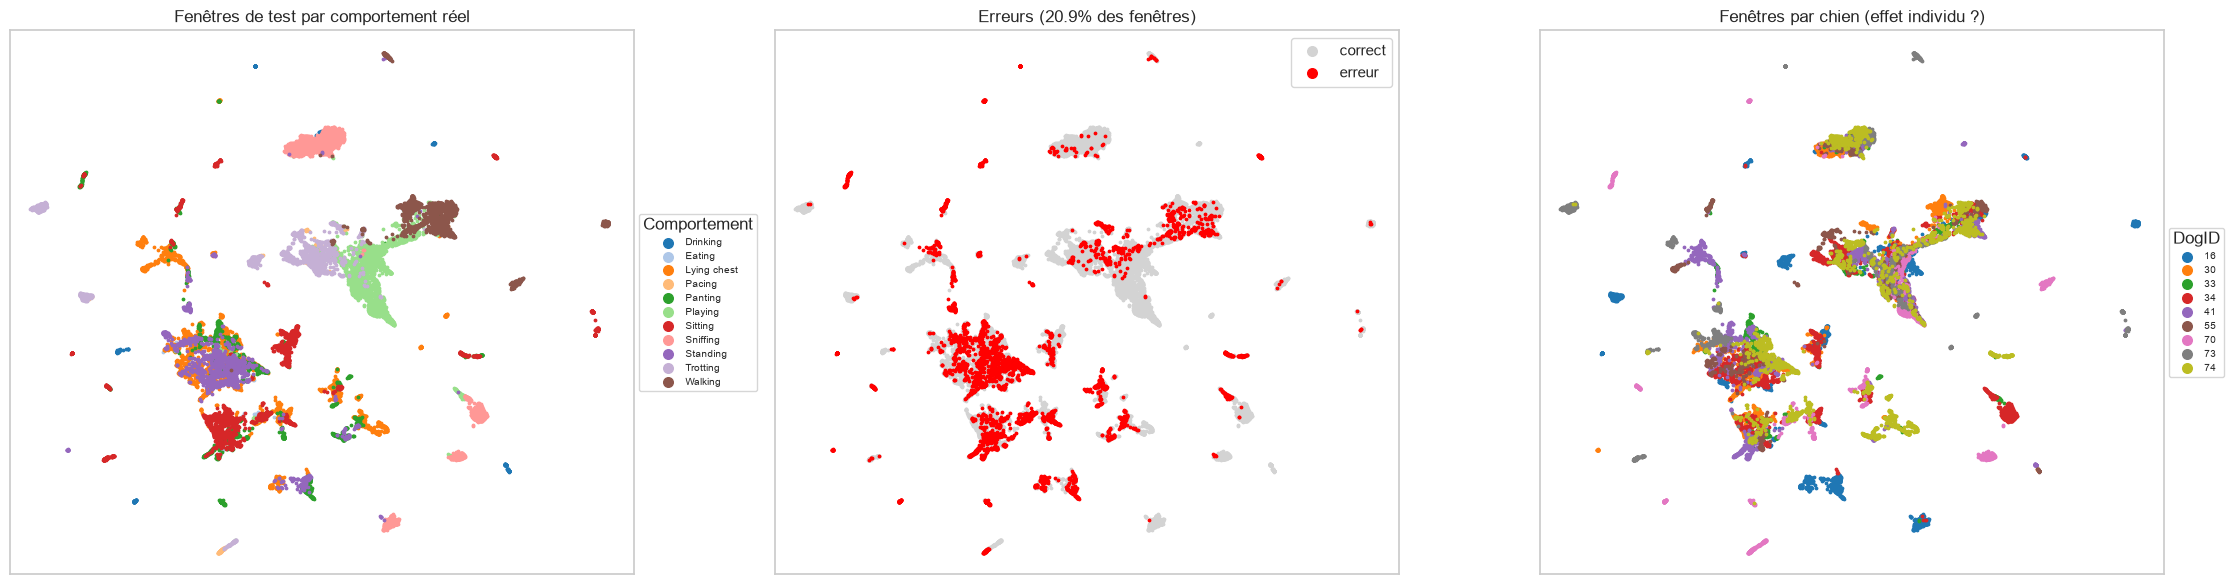

In [3]:
MAX_POINTS = 20000
vis = pred_test.sample(n=min(MAX_POINTS, len(pred_test)), random_state=cfg.RANDOM_STATE)
retenues = modeling.selected_features(general["model"], general["features"])
X_vis = test.set_index("window_id").loc[vis["window_id"], retenues].to_numpy()
emb = viz.umap_embedding(X_vis)
fig = viz.plot_umap_errors(emb, vis["target"], vis["pred"], dog_ids=vis["DogID"])
viz.savefig(fig, "07_umap_erreurs"); plt.show()

Remarques : C’est l’enseignement le plus fort de la figure. Les nombreux petits îlots isolés ont chacun une seule couleur dans le panneau de gauche, et une seule aussi dans le panneau de droite : un îlot = un chien × un comportement. Par exemple, les îlots bleus correspondent au chien 16, les roses au chien 70, les gris au chien 73.

Autrement dit, les fenêtres d’un chien dans un comportement donné se ressemblent davantage entre elles qu’elles ne ressemblent au même comportement chez les autres chiens. Et beaucoup de ces îlots sont entièrement rouges : quand un chien a une façon atypique de réaliser un comportement, le modèle se trompe sur tout le bloc. Les erreurs ne sont pas du bruit aléatoire : elles sont structurées par chien.

Cela explique directement les écarts de F1 entre chiens de test (de 0,52 à 0,79) relevés au notebook 06.

La projection UMAP des fenêtres de test fait apparaître deux régimes. Les comportements dynamiques (marche, trot, jeu, flairage) forment des nuages où les chiens se mélangent et où les erreurs restent aux frontières entre classes voisines. Les comportements statiques (couché, assis, debout, halètement) se superposent largement et concentrent la majorité des erreurs, ce qui confirme le caractère non exclusif des labels. Enfin, de nombreux îlots ne regroupent qu’un chien et un comportement, souvent mal classés en bloc : la principale source d’erreur est la variabilité individuelle, ce que confirme la dispersion des scores par chien.

## 3. Prédiction conforme

Le modèle renvoie un **ensemble** de comportements, construit pour contenir le vrai comportement avec une
probabilité d'au moins 1 - α. Un ensemble d'une seule classe signale une prédiction sûre ; un ensemble de
plusieurs classes signale une ambiguïté (souvent entre classes réellement proches).

Protocole :
1. on sépare les chiens du train en **apprentissage** (75 %) et **calibration** (25 %) ;
2. le modèle retenu est réentraîné (mêmes hyperparamètres) sur les chiens d'apprentissage ;
3. le seuil est calibré sur les chiens de calibration ;
4. couverture et taille des ensembles sont mesurées sur les chiens de **test**.

Hypothèse à discuter : la garantie suppose des exemples échangeables. Les fenêtres d'un même chien sont
corrélées ; la couverture peut donc varier d'un chien à l'autre (mesurée plus bas).

In [7]:
ALPHA = 0.10
fit_df, cal_df = conformal.calibration_split(train)
# une classe absente de l'apprentissage rendrait le modèle inutilisable : on vérifie
assert set(fit_df["target"]) == set(classes), "Classe absente des chiens d'apprentissage : changer la graine."
modele_conf = modeling.fit_clone(general, fit_df)
X_cal, y_cal = cal_df[general["features"]], le.transform(cal_df["target"])
X_te, y_te = test[general["features"]], le.transform(test["target"])
print(f"Apprentissage : {fit_df['DogID'].nunique()} chiens | calibration : {cal_df['DogID'].nunique()} chiens")

# Implémentation maison (LAC)
qhat = conformal.lac_threshold(modele_conf.predict_proba(X_cal), y_cal, ALPHA)
sets_maison = conformal.lac_sets(modele_conf.predict_proba(X_te), qhat)
resultats = {"maison_LAC": conformal.set_metrics(sets_maison, y_te)}

# MAPIE (LAC et APS)
try:
    for methode in ["lac", "aps"]:
        s = conformal.mapie_sets(modele_conf, X_cal, y_cal, X_te, ALPHA, method=methode)
        resultats[f"MAPIE_{methode.upper()}"] = conformal.set_metrics(s, y_te)
except Exception as e:
    print("MAPIE indisponible ou API différente :", repr(e))
display(pd.DataFrame(resultats).T.round(3))
print(f"Couverture visée : {1 - ALPHA:.0%}")

Apprentissage : 27 chiens | calibration : 9 chiens


,couverture,taille_moyenne,part_singletons,part_vides
maison_LAC,0.898,1.369,0.700,0.0
MAPIE_LAC,0.898,1.369,0.700,0.0
MAPIE_APS,0.929,1.557,0.602,0.0


Couverture visée : 90%


,comportement,n_fenetres,couverture,taille_moyenne
0,Drinking,431,0.717,1.265
1,Eating,195,0.692,1.821
2,Lying chest,4607,0.878,1.544
3,Pacing,390,0.790,1.715
4,Panting,2632,0.911,1.925
5,Playing,3945,0.917,1.151
6,Sitting,3210,0.740,1.461
7,Sniffing,4165,0.999,1.011
8,Standing,2234,0.781,1.750
9,Trotting,2746,0.974,1.137


,DogID,n_fenetres,couverture,taille_moyenne
0,16,4103,0.886,1.413
1,30,3473,0.898,1.433
2,33,1969,0.957,1.468
3,34,4296,0.960,1.247
4,41,3196,0.895,1.454
5,55,1749,0.934,1.208
6,70,2489,0.773,1.422
7,73,2657,0.962,1.361
8,74,3722,0.829,1.321


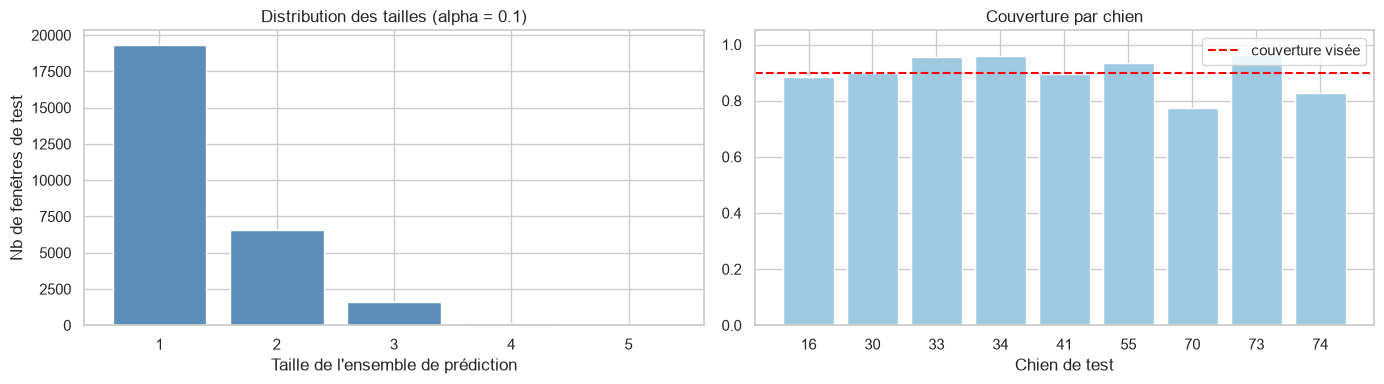

In [8]:
par_classe = conformal.coverage_by(sets_maison, y_te, le.inverse_transform(y_te), "comportement")
par_chien = conformal.coverage_by(sets_maison, y_te, test["DogID"].to_numpy(), "DogID")
display(par_classe)
display(par_chien)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sizes = sets_maison.sum(axis=1)
axes[0].bar(*np.unique(sizes, return_counts=True), color="#5b8db8")
axes[0].set_xlabel("Taille de l'ensemble de prédiction"); axes[0].set_ylabel("Nb de fenêtres de test")
axes[0].set_title(f"Distribution des tailles (alpha = {ALPHA})")
axes[1].bar(par_chien["DogID"].astype(str), par_chien["couverture"], color="#9ecae1")
axes[1].axhline(1 - ALPHA, color="red", ls="--", label="couverture visée")
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel("Chien de test"); axes[1].set_title("Couverture par chien")
axes[1].legend()
plt.tight_layout(); viz.savefig(fig, "07_conforme"); plt.show()

,alpha,couverture_visee,couverture,taille_moyenne,part_singletons,part_vides
0,0.01,0.99,0.977,2.626,0.322,0.000
1,0.02,0.98,0.962,1.997,0.434,0.000
2,0.05,0.95,0.935,1.599,0.581,0.000
3,0.10,0.90,0.898,1.369,0.700,0.000
4,0.15,0.85,0.844,1.166,0.841,0.000
5,0.20,0.80,0.779,0.999,0.980,0.011
6,0.30,0.70,0.651,0.751,0.751,0.249


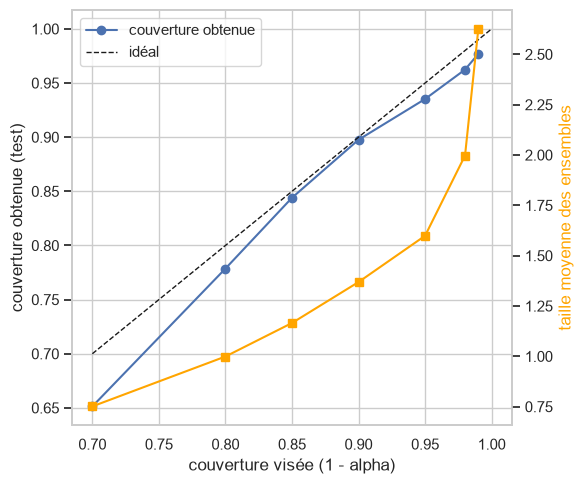

In [9]:
# Compromis couverture / taille selon alpha (implémentation maison)
p_cal, p_te = modele_conf.predict_proba(X_cal), modele_conf.predict_proba(X_te)
courbe = []
for a in [0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]:
    s = conformal.lac_sets(p_te, conformal.lac_threshold(p_cal, y_cal, a))
    courbe.append({"alpha": a, "couverture_visee": 1 - a, **conformal.set_metrics(s, y_te)})
courbe = pd.DataFrame(courbe)
display(courbe.round(3))
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(courbe["couverture_visee"], courbe["couverture"], marker="o", label="couverture obtenue")
ax.plot([0.7, 1], [0.7, 1], "k--", lw=1, label="idéal")
ax2 = ax.twinx(); ax2.plot(courbe["couverture_visee"], courbe["taille_moyenne"], color="orange", marker="s")
ax2.set_ylabel("taille moyenne des ensembles", color="orange"); ax2.grid(False)
ax.set_xlabel("couverture visée (1 - alpha)"); ax.set_ylabel("couverture obtenue (test)"); ax.legend(loc="upper left")
plt.tight_layout(); viz.savefig(fig, "07_courbe_conforme"); plt.show()

Conclusion : En prédiction simple, l’exactitude est de 79 %. En ajoutant en moyenne seulement 0,37 classe par fenêtre, on atteint 90 % de couverture. Autrement dit, quand le modèle se trompe, la bonne réponse est très souvent sa deuxième proposition. Ceci vient conforter les résultats de la prédiction flexible prenant en compte behavior 2 / 3.

L’incertitude est donc concentrée et limitée : quand le modèle hésite, c’est entre deux ou trois classes, pas entre toutes.

La garantie est marginale : elle vaut en moyenne sur l’ensemble des fenêtres, pas chien par chien. Pour un chien atypique, le modèle est confiant à tort, et ses ensembles sont trop petits.

Avec α = 0,10, la prédiction conforme atteint une couverture de test de 89,7 % pour une taille moyenne d’ensemble de 1,37 : 70 % des fenêtres reçoivent un seul comportement, et les autres en reçoivent deux ou trois. La garantie est tenue en moyenne, avec une légère sous-couverture systématique aux niveaux de confiance élevés, attribuable aux différences entre chiens de calibration et chiens de test. Elle n’est en revanche pas tenue chien par chien : la couverture va de 77 % (chien 70) à 96 %. Le chien 70, déjà le moins amélioré par le lissage et visible en blocs d’erreurs dans la projection UMAP, illustre la limite commune à ces analyses : la variabilité individuelle, que la calibration ne peut pas anticiper pour un chien atypique.